# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Daffa Aufa Afif| 5054251022 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
from math import ceil, floor
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from pathlib import Path
from sklearn.svm import SVC
from sklearn.decomposition import PCA

In [2]:
import kagglehub

# Download latest version
if not Path("data.csv"):
    path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
    path +='data.csv'
    print("Path to dataset files:", path)
else:
    path = Path("data.csv")

/media/dff/Elements1/Codex/Works/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv(path)
print(df.head())


         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

In [4]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
baris,kolom = df.shape
print("Kolom:", kolom)
print("Baris:", df.shape[0])
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

Kolom: 33
Baris: 569
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se    

Diketahui bahwa kolom `Unnamed: 32` hanya berisi `NaN`, maka akan di-drop

In [5]:
df = df.drop('Unnamed: 32', axis=1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

/media/dff/Elements1/Codex/Works/tmp/ipykernel_4/169406796.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df['diagnosis'].value_counts().index, y=df['diagnosis'].value_counts(), palette='viridis')


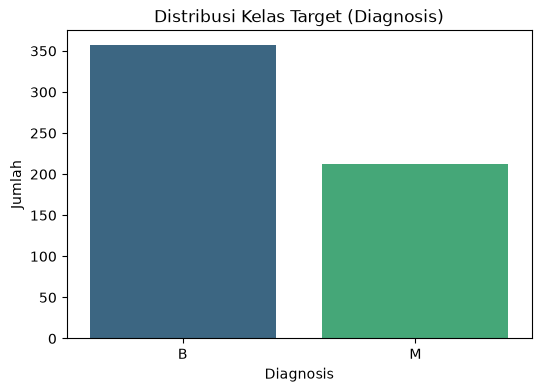

In [6]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

plt.figure(figsize=(6, 4))
sns.barplot(x=df['diagnosis'].value_counts().index, y=df['diagnosis'].value_counts(), palette='viridis')

plt.title('Distribusi Kelas Target (Diagnosis)')
plt.xlabel('Diagnosis')
plt.ylabel('Jumlah')
plt.show()

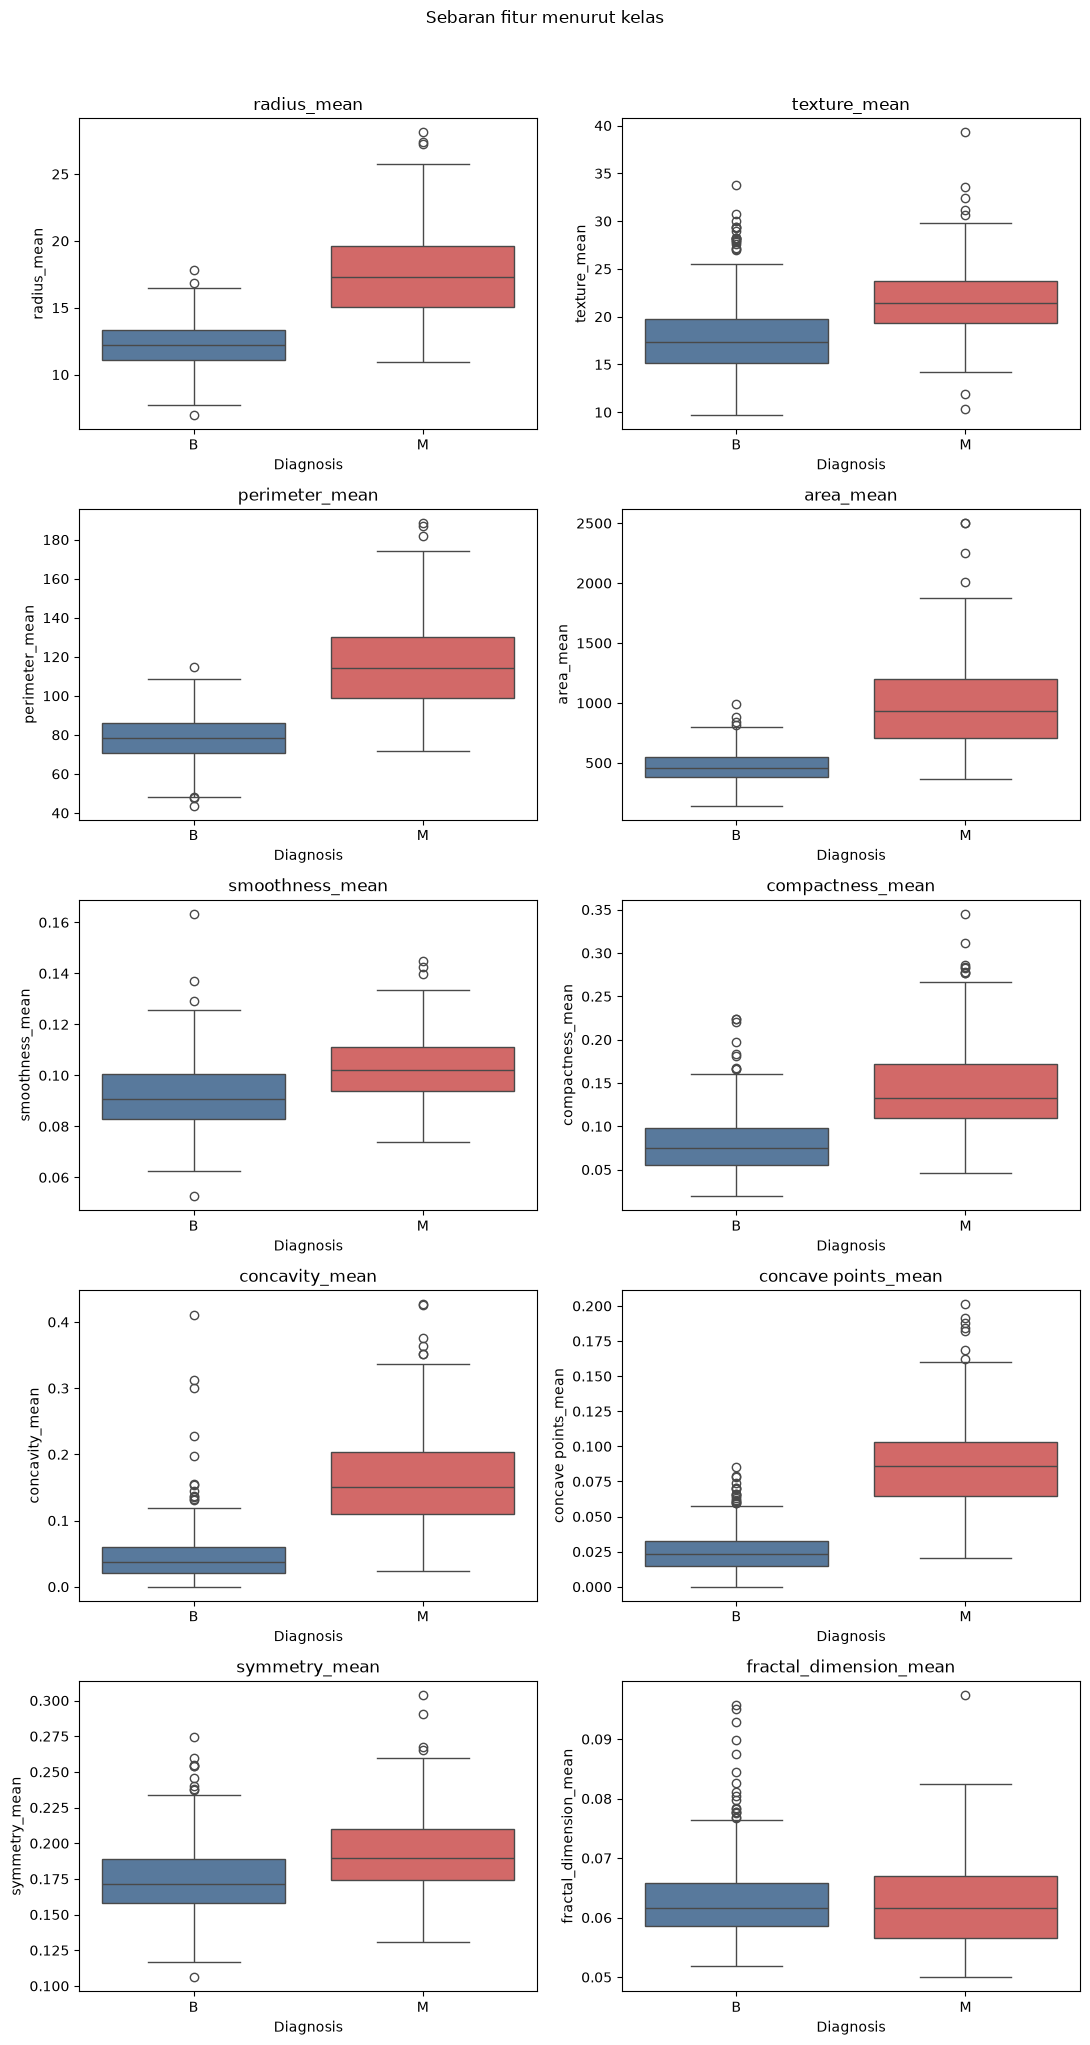

In [7]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau pairplot), dibedakan berdasarkan kelas target.
# Ini membantu melihat apakah ada fitur yang punya batas pemisah yang jelas (linear) antar kelas, atau justru tumpang tindih.
features_to_show = [c for c in df.columns if c.endswith("_mean")]
fig, axes = plt.subplots(5, 2, figsize=(11, 20))
for ax, feature in zip(axes.flat, features_to_show):
    sns.boxplot(data=df, x="diagnosis", y=feature, hue="diagnosis",
                order=["B", "M"], palette={"B": "#4c78a8", "M": "#e45756"},
                legend=False, ax=ax)
    ax.set(xlabel="Diagnosis", title=feature)
plt.suptitle("Sebaran fitur menurut kelas", y=1.02)
plt.tight_layout()
plt.show()

Semuanya timpang tindih. Namun, fitur seperti `radius_mean`, `perimeter_mean`, dan `concave point_mean` menunjukkan tingkat tumpang tindih yang minimal

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [8]:
y = df["diagnosis"].map({"B": 0, "M": 1})

In [9]:
print(df.drop(columns=['id','diagnosis']).corrwith(y).abs().sort_values(ascending=False))

concave points_worst       0.793566
perimeter_worst            0.782914
concave points_mean        0.776614
radius_worst               0.776454
perimeter_mean             0.742636
area_worst                 0.733825
radius_mean                0.730029
area_mean                  0.708984
concavity_mean             0.696360
concavity_worst            0.659610
compactness_mean           0.596534
compactness_worst          0.590998
radius_se                  0.567134
perimeter_se               0.556141
area_se                    0.548236
texture_worst              0.456903
smoothness_worst           0.421465
symmetry_worst             0.416294
texture_mean               0.415185
concave points_se          0.408042
smoothness_mean            0.358560
symmetry_mean              0.330499
fractal_dimension_worst    0.323872
compactness_se             0.292999
concavity_se               0.253730
fractal_dimension_se       0.077972
smoothness_se              0.067016
fractal_dimension_mean     0

In [10]:
X = df.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")

korelasi = X.corrwith(y).abs().sort_values(ascending=False)
selected = korelasi[korelasi > 0.5].index.tolist()
for i in selected:
    print(i)

concave points_worst
perimeter_worst
concave points_mean
radius_worst
perimeter_mean
area_worst
radius_mean
area_mean
concavity_mean
concavity_worst
compactness_mean
compactness_worst
radius_se
perimeter_se
area_se


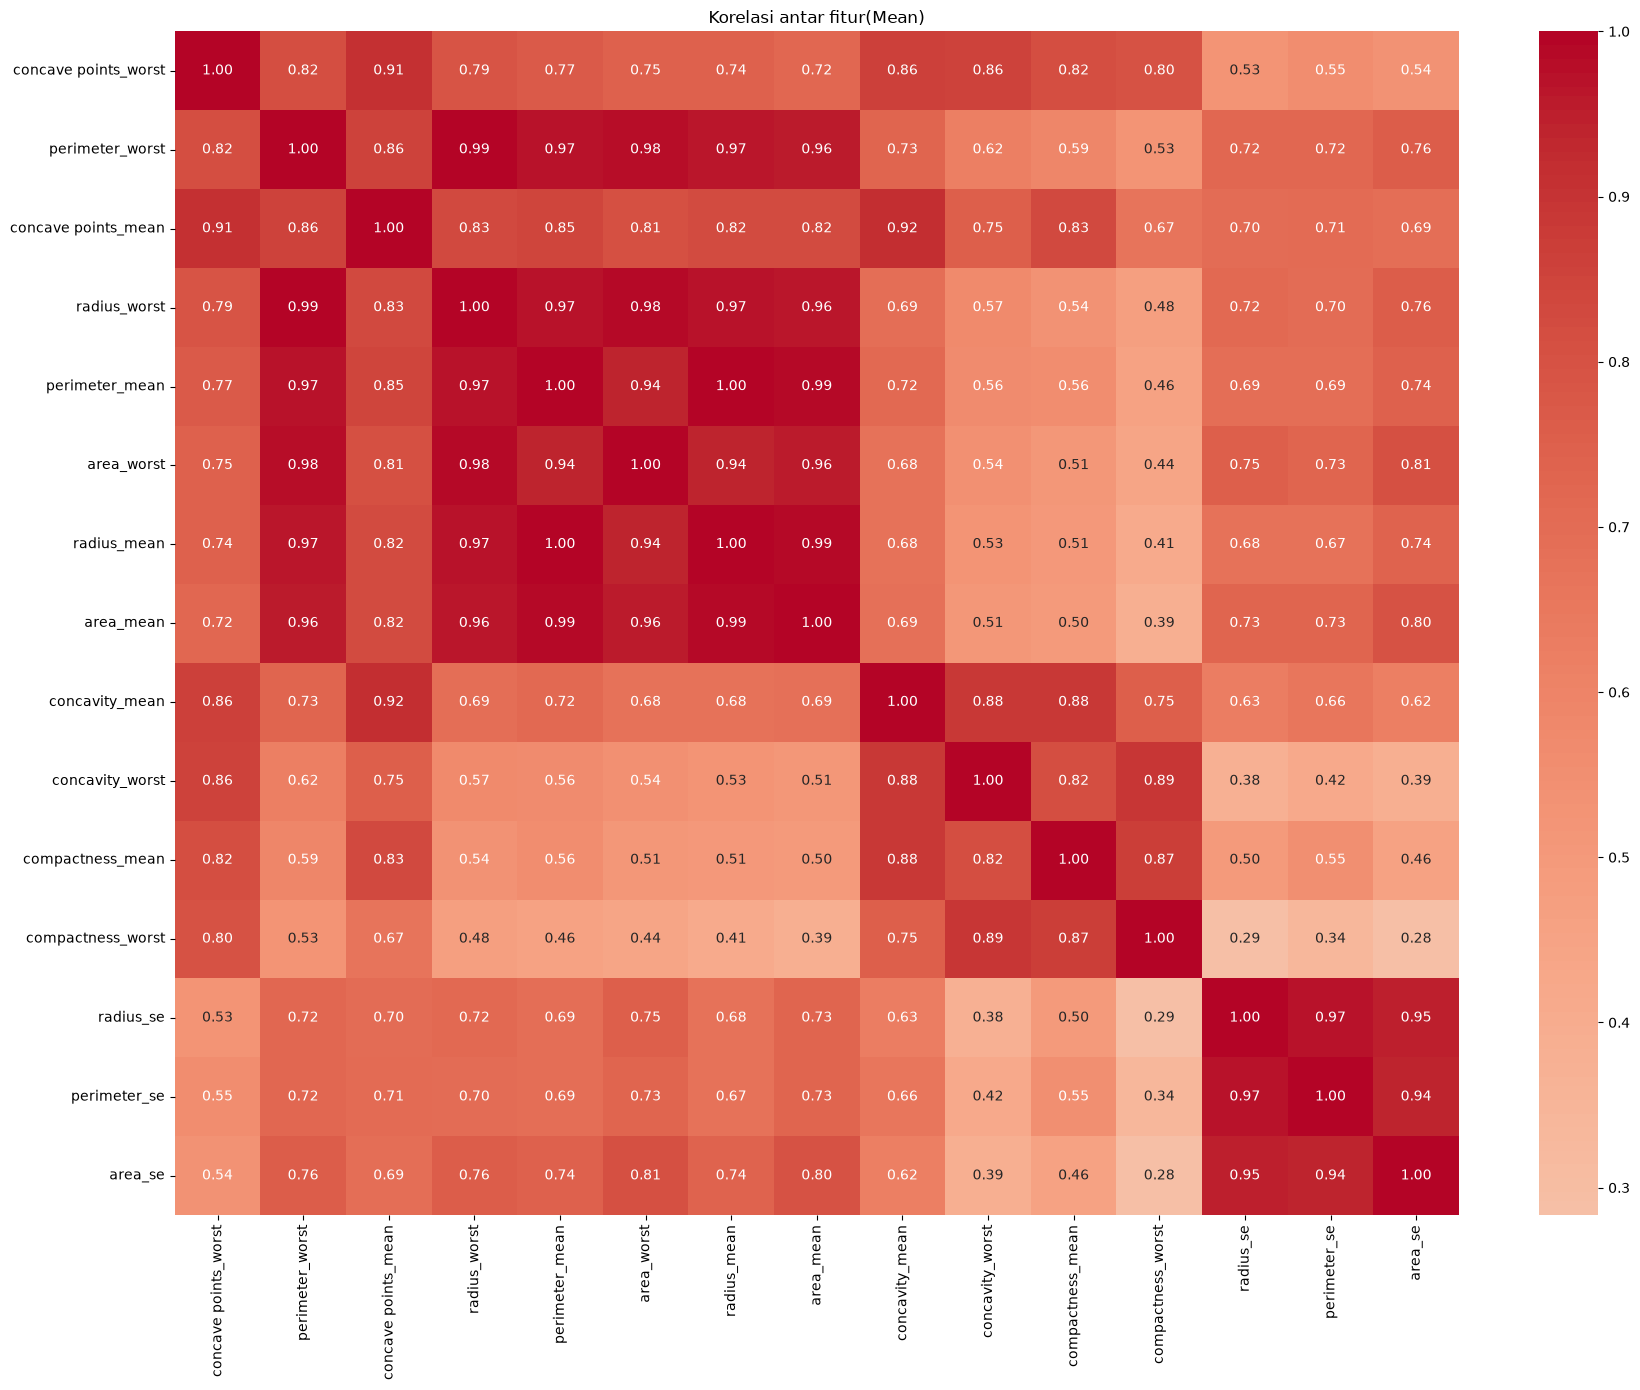

In [11]:
plt.figure(figsize=(18, 14))
sns.heatmap(df[selected].corr(method="pearson"), cmap='coolwarm',center=0,annot=True,fmt='.2f')
plt.title("Korelasi antar fitur(Mean)")
plt.tight_layout()
plt.show()

fitur fitur meliki keterkaitan yang cukup tinggi, maka yang akan di drop adalah [radius_worst, perimeter_mean, area_worst,radius_mean, area_mean, perimeter_se, area_se] (korelasi antar fitur>0.95)

In [12]:
selected = [i for i in selected if i not in ['radius_worst', 'perimeter_mean', 'area_worst','radius_mean', 'area_mean', 'perimeter_se', 'area_se']]
print(selected)

['concave points_worst', 'perimeter_worst', 'concave points_mean', 'concavity_mean', 'concavity_worst', 'compactness_mean', 'compactness_worst', 'radius_se']


# 2. Preprocessing

In [13]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
print(df.isna().sum().sum())
clean = [*selected,'diagnosis']
df_clean = df[clean].copy()
print(df_clean.head())
print(df_clean.shape)

0
   concave points_worst  perimeter_worst  concave points_mean  concavity_mean  \
0                0.2654           184.60              0.14710          0.3001   
1                0.1860           158.80              0.07017          0.0869   
2                0.2430           152.50              0.12790          0.1974   
3                0.2575            98.87              0.10520          0.2414   
4                0.1625           152.20              0.10430          0.1980   

   concavity_worst  compactness_mean  compactness_worst  radius_se diagnosis  
0           0.7119           0.27760             0.6656     1.0950         M  
1           0.2416           0.07864             0.1866     0.5435         M  
2           0.4504           0.15990             0.4245     0.7456         M  
3           0.6869           0.28390             0.8663     0.4956         M  
4           0.4000           0.13280             0.2050     0.7572         M  
(569, 9)


In [14]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
X= df_clean.drop(columns=['diagnosis'])
y = df_clean['diagnosis']
X_train, X_test, y_train,  y_test = train_test_split(X,y,test_size=0.20,random_state=22, stratify=y)

**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [15]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.
scaler =StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Eksperimen Model

In [16]:
# Setiap entri res menyimpan model serta prediksi train dan test.
res = {}

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [17]:
# Arsitektur dan C sesuai rancanganmu.
linear = SVC(kernel='linear', C=1.0, random_state=22)
linear.fit(X_train_scaled, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",22
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [18]:
# predict hanya menerima data fitur; y_test dipakai saat evaluasi.
res['Linear'] = {
    'model': linear,
    'pred_train': linear.predict(X_train_scaled),
    'pred_test': linear.predict(X_test_scaled),
    'eksperimen': 'Baseline'
}
print('Prediksi Linear (10 pertama):', res['Linear']['pred_test'][:10])

Prediksi Linear (10 pertama): ['B' 'M' 'M' 'B' 'B' 'B' 'B' 'M' 'M' 'M']


## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [19]:
rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=22)
rbf.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",22
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [20]:
res['RBF'] = {
    'model': rbf,
    'pred_train': rbf.predict(X_train_scaled),
    'pred_test': rbf.predict(X_test_scaled),
    'eksperimen': 'Baseline'
}
print('Prediksi RBF (10 pertama):', res['RBF']['pred_test'][:10])

Prediksi RBF (10 pertama): ['B' 'M' 'M' 'B' 'B' 'B' 'B' 'M' 'M' 'M']


## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [21]:
c_values = [0.01, 0.1, 1, 10, 100]
for c in c_values:
    # C=1 sudah dilatih sebagai baseline RBF.
    model = rbf if c == 1 else SVC(kernel='rbf', C=c, gamma='scale', random_state=22).fit(X_train_scaled, y_train)
    res[f'RBF C={c:g}'] = {
        'model': model,
        'pred_train': model.predict(X_train_scaled),
        'pred_test': model.predict(X_test_scaled),
        'eksperimen': 'Variasi C'
    }
print('Model dalam res:', list(res))

Model dalam res: ['Linear', 'RBF', 'RBF C=0.01', 'RBF C=0.1', 'RBF C=1', 'RBF C=10', 'RBF C=100']


In [22]:
c_results = pd.DataFrame([
    {
        'C': c,
        'Accuracy Train': accuracy_score(y_train, res[f'RBF C={c:g}']['pred_train']),
        'Accuracy Test': accuracy_score(y_test, res[f'RBF C={c:g}']['pred_test'])
    }
    for c in c_values
])
display(c_results.round(4))

,C,Accuracy Train,Accuracy Test
0,0.01,0.8703,0.8684
1,0.10,0.9275,0.9211
2,1.00,0.9604,0.9474
3,10.00,0.9692,0.9649
4,100.00,0.9736,0.9561


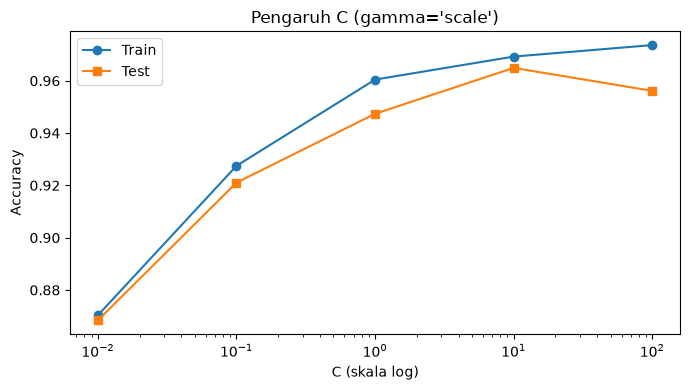

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(c_results['C'], c_results['Accuracy Train'], marker='o', label='Train')
ax.plot(c_results['C'], c_results['Accuracy Test'], marker='s', label='Test')
ax.set_xscale('log')
ax.set(xlabel='C (skala log)', ylabel='Accuracy', title="Pengaruh C (gamma='scale')")
ax.legend()
plt.tight_layout()
plt.show()

### 3.4 Pengaruh gamma pada kernel RBF

Setelah `C`, coba beberapa nilai `gamma` dengan `C=1` tetap. Prediksi masing-masing model juga disimpan di `res`.

In [24]:
gamma_values = [0.001, 0.01, 0.1, 1, 10]
for gamma in gamma_values:
    model = SVC(kernel='rbf', C=1.0, gamma=gamma, random_state=22)
    model.fit(X_train_scaled, y_train)
    res[f'RBF gamma={gamma:g}'] = {
        'model': model,
        'pred_train': model.predict(X_train_scaled),
        'pred_test': model.predict(X_test_scaled),
        'eksperimen': 'Variasi gamma'
    }
print('Model dalam res:', list(res))

Model dalam res: ['Linear', 'RBF', 'RBF C=0.01', 'RBF C=0.1', 'RBF C=1', 'RBF C=10', 'RBF C=100', 'RBF gamma=0.001', 'RBF gamma=0.01', 'RBF gamma=0.1', 'RBF gamma=1', 'RBF gamma=10']


,gamma,Accuracy Train,Accuracy Test
0,0.001,0.9165,0.9035
1,0.010,0.9341,0.9298
2,0.100,0.9582,0.9474
3,1.000,0.9736,0.9386
4,10.000,1.0000,0.6754


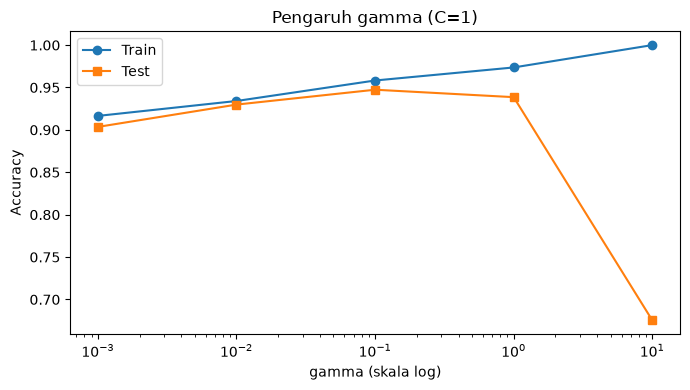

In [25]:
gamma_results = pd.DataFrame([
    {
        'gamma': gamma,
        'Accuracy Train': accuracy_score(y_train, res[f'RBF gamma={gamma:g}']['pred_train']),
        'Accuracy Test': accuracy_score(y_test, res[f'RBF gamma={gamma:g}']['pred_test'])
    }
    for gamma in gamma_values
])
display(gamma_results.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(gamma_results['gamma'], gamma_results['Accuracy Train'], marker='o', label='Train')
ax.plot(gamma_results['gamma'], gamma_results['Accuracy Test'], marker='s', label='Test')
ax.set_xscale('log')
ax.set(xlabel='gamma (skala log)', ylabel='Accuracy', title='Pengaruh gamma (C=1)')
ax.legend()
plt.tight_layout()
plt.show()

# 4. Evaluasi Model

In [26]:
# Metrik semua model dihitung dari prediksi yang sudah disimpan dalam res.
rows = []
for nama, hasil in res.items():
    model = hasil['model']
    pred_test = hasil['pred_test']
    rows.append({
        'Model': nama,
        'Eksperimen': hasil['eksperimen'],
        'Kernel': model.kernel,
        'C': model.C,
        'gamma': model.gamma if model.kernel == 'rbf' else '—',
        'Accuracy Train': accuracy_score(y_train, hasil['pred_train']),
        'Accuracy Test': accuracy_score(y_test, pred_test),
        'Precision M': precision_score(y_test, pred_test, pos_label='M', zero_division=0),
        'Recall M': recall_score(y_test, pred_test, pos_label='M', zero_division=0),
        'F1 M': f1_score(y_test, pred_test, pos_label='M', zero_division=0),
        'Support Vectors': int(model.n_support_.sum())
    })
evaluasi = pd.DataFrame(rows).set_index('Model')
display(evaluasi.round(4))

,Eksperimen,Kernel,C,gamma,Accuracy Train,Accuracy Test,Precision M,Recall M,F1 M,Support Vectors
Model,,,,,,,,,,
Linear,Baseline,linear,1.00,—,0.9473,0.9474,0.9091,0.9524,0.9302,63
RBF,Baseline,rbf,1.00,scale,0.9604,0.9474,0.9500,0.9048,0.9268,95
RBF C=0.01,Variasi C,rbf,0.01,scale,0.8703,0.8684,1.0000,0.6429,0.7826,340
RBF C=0.1,Variasi C,rbf,0.10,scale,0.9275,0.9211,0.9024,0.8810,0.8916,158
RBF C=1,Variasi C,rbf,1.00,scale,0.9604,0.9474,0.9500,0.9048,0.9268,95
RBF C=10,Variasi C,rbf,10.00,scale,0.9692,0.9649,0.9524,0.9524,0.9524,72
RBF C=100,Variasi C,rbf,100.00,scale,0.9736,0.9561,0.9111,0.9762,0.9425,61
RBF gamma=0.001,Variasi gamma,rbf,1.00,0.001,0.9165,0.9035,0.9189,0.8095,0.8608,232
RBF gamma=0.01,Variasi gamma,rbf,1.00,0.01,0.9341,0.9298,0.9250,0.8810,0.9024,124


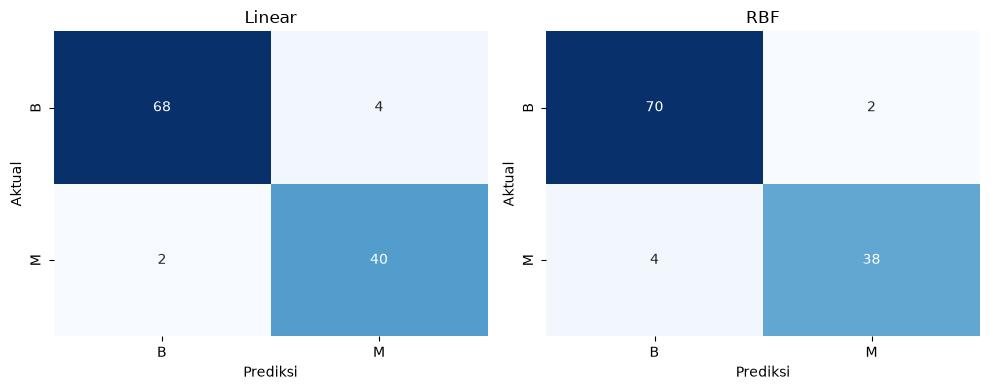

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nama in zip(axes, ['Linear', 'RBF']):
    cm = confusion_matrix(y_test, res[nama]['pred_test'], labels=['B', 'M'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['B', 'M'], yticklabels=['B', 'M'], ax=ax)
    ax.set(xlabel='Prediksi', ylabel='Aktual', title=nama)
plt.tight_layout()
plt.show()

In [28]:
display(evaluasi[['Eksperimen', 'Support Vectors']])
print('Linear:', res['Linear']['model'].n_support_.sum())
print('RBF:', res['RBF']['model'].n_support_.sum())

,Eksperimen,Support Vectors
Model,,
Linear,Baseline,63
RBF,Baseline,95
RBF C=0.01,Variasi C,340
RBF C=0.1,Variasi C,158
RBF C=1,Variasi C,95
RBF C=10,Variasi C,72
RBF C=100,Variasi C,61
RBF gamma=0.001,Variasi gamma,232
RBF gamma=0.01,Variasi gamma,124


Linear: 63
RBF: 95


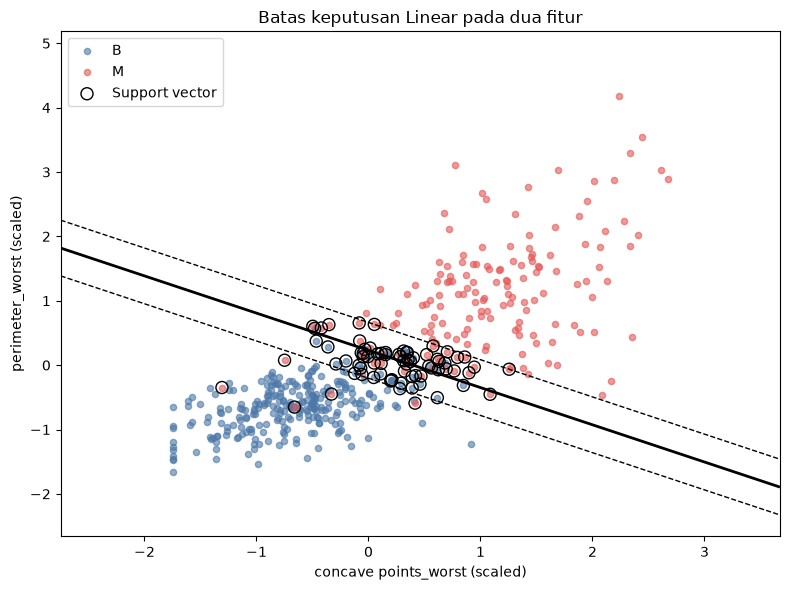

In [29]:
# Dua fitur dipilih untuk menggambar batas keputusan. Model ini dilatih ulang
# pada dua fitur saja; plot tidak identik dengan model utama yang memakai 8 fitur.
dua_fitur = ['concave points_worst', 'perimeter_worst']
scaler_2d = StandardScaler()
X_train_2d = scaler_2d.fit_transform(X_train[dua_fitur])

# Visualisasikan kernel baseline dengan F1 M test lebih tinggi.
nama_plot = evaluasi.loc[['Linear', 'RBF'], 'F1 M'].idxmax()
model_utama = res[nama_plot]['model']
model_2d = SVC(kernel=model_utama.kernel, C=model_utama.C,
               gamma=model_utama.gamma, random_state=22)
model_2d.fit(X_train_2d, y_train)

x_min, x_max = X_train_2d[:, 0].min()-1, X_train_2d[:, 0].max()+1
y_min, y_max = X_train_2d[:, 1].min()-1, X_train_2d[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                     np.linspace(y_min, y_max, 250))
z = model_2d.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(8, 6))
for label, color in [('B', '#4c78a8'), ('M', '#e45756')]:
    mask = (y_train.to_numpy() == label)
    ax.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], s=20,
               alpha=0.6, color=color, label=label)
ax.contour(xx, yy, z, levels=[-1, 0, 1], colors='black',
           linestyles=['--', '-', '--'], linewidths=[1, 2, 1])
ax.scatter(model_2d.support_vectors_[:, 0], model_2d.support_vectors_[:, 1],
           s=75, facecolors='none', edgecolors='black', label='Support vector')
ax.set(xlabel=dua_fitur[0]+' (scaled)', ylabel=dua_fitur[1]+' (scaled)',
       title=f'Batas keputusan {nama_plot} pada dua fitur')
ax.legend()
plt.tight_layout()
plt.show()

# 5. Analisis

## 5.1 Hasil Analisis

**EDA dan preprocessing:** 
Dataset berisi 569 sampel. Kolom `Unnamed: 32` yang seluruhnya kosong dan kolom `id` tidak digunakan sebagai fitur. Dari 30 fitur numerik, dipilih 15 fitur dengan korelasi absolut terhadap diagnosis di atas 0,5, lalu menghapus tujuh fitur yang saling berkorelasi tinggi sehingga tersisa delapan fitur. Data dibagi 80:20 secara *stratified* (455 train dan 114 test). `StandardScaler` dipelajari pada train dan hanya diterapkan pada test.

**Perbandingan kernel Linear dan RBF:** 
Pada `C=1`, keduanya mencapai accuracy test **0,9474**, tetapi kesalahannya tidak sama. Linear memperoleh precision/recall/F1 kelas M sebesar **0,9091/0,9524/0,9302**, sedangkan RBF dengan `gamma='scale'` memperoleh **0,9500/0,9048/0,9268**. Dari confusion matrix, Linear melewatkan **2** dari 42 sampel M dan keliru menandai **4** sampel B sebagai M; RBF melewatkan **4** sampel M dan keliru menandai **2** sampel B sebagai M. Jadi, pada pembagian data ini Linear lebih baik dalam menangkap kelas M, sementara RBF lebih jarang memberi peringatan M yang keliru. Perbedaan pada satu test set ini belum cukup untuk menyimpulkan satu kernel selalu lebih unggul. Tumpang tindih pada boxplot tiap fitur juga tidak dengan sendirinya menjelaskan batas keputusan model yang memakai delapan fitur sekaligus.

**Pengaruh `C` pada RBF (`gamma='scale'`):**
Pada `C=0,01`, accuracy train/test hanya **0,8703/0,8684** dan recall M **0,6429**: model cenderung terlalu sederhana. Peningkatan `C` sampai **10** menaikkan accuracy test ke nilai tertinggi dari nilai yang dicoba, **0,9649**, dengan precision, recall, dan F1 M masing-masing **0,9524**. Ketika `C` dinaikkan menjadi **100**, accuracy train bertambah dari **0,9692** menjadi **0,9736**, tetapi accuracy test turun dari **0,9649** menjadi **0,9561**. Gap train–test yang membesar memberi indikasi awal overfitting pada split ini, meski recall M pada `C=100` justru naik menjadi **0,9762**. Karena itu, pemilihan `C` bergantung pula pada metrik yang diprioritaskan.

**Pengaruh `gamma` pada RBF (`C=1`):** 
Pada `gamma=0,001`, accuracy train/test **0,9165/0,9035** dan recall M **0,8095**. Nilai `gamma=0,1` menaikkan accuracy test menjadi **0,9474**. Pada `gamma=1`, train meningkat ke **0,9736** tetapi test turun ke **0,9386**. Kasus paling jelas terjadi pada `gamma=10`: accuracy train **1,0000**, sedangkan test hanya **0,6754** dan recall M **0,1429**. Batas keputusan yang terlalu menyesuaikan data train pada pengaturan ini tidak berhasil mengenali sebagian besar sampel M di test.

**Support vector dan batas interpretasi:**
Model Linear baseline memakai **63** support vector, sementara RBF baseline **95**. Jumlah ini menggambarkan titik yang menopang batas keputusan masing-masing model, tetapi bukan ukuran tunggal kualitas model. Grafik batas keputusan di eksperimen dibuat dari model Linear yang dilatih ulang pada **dua** fitur, sehingga grafik tersebut membantu ilustrasi dan tidak mewakili batas persis model utama delapan fitur.


# 6. Kesimpulan dan Saran

## Kesimpulan
Eksperimen menunjukkan bahwa SVM Linear dan RBF dengan C=1 menghasilkan akurasi test yang sama, yaitu 0,9474, tetapi membuat jenis kesalahan yang berbeda. Linear memiliki recall kelas M lebih tinggi (0,9524), sedangkan RBF memiliki precision kelas M lebih tinggi (0,9500). Jadi, akurasi yang sama belum tentu berarti perilaku kedua model sama.
Perubahan parameter memberi pengaruh yang jelas. Pada kernel RBF, C=10 menghasilkan akurasi test tertinggi di antara konfigurasi yang dicoba, yaitu 0,9649. Sebaliknya, gamma=10 menghasilkan akurasi train 1,0000 tetapi akurasi test hanya 0,6754. Temuan ini menunjukkan bahwa model yang sangat cocok dengan data train belum tentu bekerja baik pada data test.
## Saran
Eksperimen ini menggunakan 8 dari 30 fitur numerik setelah seleksi berdasarkan korelasi. Eksperimen berikutnya dapat membandingkan hasil tersebut dengan model yang memakai lebih banyak fitur, termasuk seluruh 30 fitur. Fitur yang dibuang karena saling berkorelasi mungkin masih menyimpan informasi yang berguna ketika digunakan bersama oleh SVM, sehingga pengaruh jumlah fitur terhadap akurasi perlu diuji.
Selain itu, C dan gamma dapat dicari secara bersamaan dengan nilai yang lebih beragam. Pemilihan fitur dan parameter sebaiknya dilakukan melalui validasi silang pada data train, lalu konfigurasi terpilih diuji pada test set. Dengan begitu, dapat dinilai apakah peningkatan akurasi seperti pada C=10 tetap konsisten dan bukan hanya berlaku pada satu pembagian data.